In [34]:
import rapids_singlecell as rsc
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
import pandas as pd
import os
import cupyx as cpx
import scipy

# rsc.get.anndata_to_GPU(adata)

In [35]:
PRT_names=["APE","BM","COL","ILE","LIV","LN","PANC","PROS","STO"]
PRTs = []
for name in PRT_names:
    sm = sc.read(f'PRT_{name}_SM.h5ad')
    sm.obs['phenotype'] = sm.obs['phenotype'].str.replace('likely-', '').astype('category')

    # Define your mapping from fine to broad phenotype
    phenotype_mapping = {
        'Stroma': 'Mesenchymal-Stromal',
        'Endothelial': 'Endothelial',
        'Epithelial': 'Epithelial',
        'Myeloid': 'Myeloid',
        'Immune': 'Lymphoid-Other',
        'Dendritic Cells': 'Lymphoid-DC',
        'T Cells': 'Lymphoid-T',
        'B Cells': 'Lymphoid-B',
    }

    # Apply the mapping
    sm.obs['phenotype_broad'] = sm.obs['phenotype'].map(phenotype_mapping)

    PRT = sc.read(f'../SAHAMaxFuse/PRT_{name}.h5ad')
    PRT.obs['phenotype'] = sm.obs['phenotype'].astype('category')
    PRT.obs['phenotype_broad'] = sm.obs['phenotype_broad'].astype('category')
    
    PRT.obs['organ'] = name

    PRTs.append(PRT)
PRT = ad.concat(PRTs, uns_merge='first')
PRT

AnnData object with n_obs × n_vars = 3436020 × 64
    obs: 'Area', 'CenterX_global_px', 'CenterY_global_px', 'cell_id', 'batch', 'SAHA_name', 'leiden', 'leiden_0.5', 'leiden_1', 'celltype_mf', 'phenotype', 'phenotype_broad', 'organ'
    uns: 'SAHA_name_colors', 'leiden', 'leiden_0.5_colors', 'leiden_1_colors', 'neighbors', 'pca', 'umap', 'leiden_2_colors', 'leiden_3_colors'
    obsm: 'X_harmony', 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_after_harmony', 'X_umap_before_harmony', 'spatial'
    layers: 'normalized', 'raw'

In [36]:
PRT.obs['celltype_mf'] = PRT.obs['celltype_mf'].astype('category')
PRT.obs['celltype_mf'] = PRT.obs['celltype_mf'].cat.reorder_categories(
    sorted(PRT.obs['celltype_mf'].unique()), ordered=True
)

PRT.obs['phenotype_broad'] = PRT.obs['phenotype_broad'].astype('category')
PRT.obs['phenotype_broad'] = PRT.obs['phenotype_broad'].cat.reorder_categories(
    sorted(PRT.obs['phenotype_broad'].unique()), ordered=True
)

In [37]:
palette_organ = [
    '#8B0000', #APE
    '#800000', #BM
    '#003366', #COL
    '#005F6A', #ILE
    '#A68B00', #LIV
    '#2A6365', #LN
    '#550033', #PANC
    '#004D1A', #PROS
    '#C1440E', #STO
]

'''palette_PRTmf = [
    '#ff7f0e', #endo
    '#1f77b4', #epi
    '#f2e205', #ery
    'darkgray', #immune
    '#ff99cc', #B
    '#7DD520', #DC
    '#17becf', #Other
    '#7f7f7f', #Plasma
    '#8c564b', #T
    '#2ca02c', #Mesen
    'gray', #mixed
    '#d62728', #Myeloid
    '#9467bd', #Neuro
    'lightgray', #None
    '#ff33cc', #Stem
]

palette_PRTbroad = [
    '#ff7f0e', #endo
    '#1f77b4', #epi  
    '#ff99cc', #B
    '#7DD520', #DC
    '#17becf', #Other
    '#8c564b', #T
    '#2ca02c', #Mesen
    '#d62728', #Myeloid
]'''

# 1. Organ
sc.pl.embedding(PRT, basis='X_umap_after_harmony', color='organ', palette=palette_organ, show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.savefig("umap_organ.jpg", dpi=300, bbox_inches='tight', transparent=True)
plt.close()

'''# 2. Celltype MF
sc.pl.embedding(PRT, basis='X_umap_after_harmony', color='celltype_mf', palette=palette_PRTmf, show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.savefig("umap_maxfuse.jpg", dpi=300, bbox_inches='tight', transparent=True)
plt.close()

# 3. Phenotype Broad
sc.pl.embedding(PRT, basis='X_umap_after_harmony', color='phenotype_broad', palette=palette_PRTbroad, show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.savefig("umap_scimap.jpg", dpi=300, bbox_inches='tight', transparent=True)
plt.close()'''

'# 2. Celltype MF\nsc.pl.embedding(PRT, basis=\'X_umap_after_harmony\', color=\'celltype_mf\', palette=palette_PRTmf, show=False)\nplt.gca().spines[\'top\'].set_visible(False)\nplt.gca().spines[\'right\'].set_visible(False)\nplt.gca().spines[\'left\'].set_visible(False)\nplt.gca().spines[\'bottom\'].set_visible(False)\nplt.gca().set_title(\'\')\nplt.axis(\'off\')\nplt.savefig("umap_maxfuse.jpg", dpi=300, bbox_inches=\'tight\', transparent=True)\nplt.close()\n\n# 3. Phenotype Broad\nsc.pl.embedding(PRT, basis=\'X_umap_after_harmony\', color=\'phenotype_broad\', palette=palette_PRTbroad, show=False)\nplt.gca().spines[\'top\'].set_visible(False)\nplt.gca().spines[\'right\'].set_visible(False)\nplt.gca().spines[\'left\'].set_visible(False)\nplt.gca().spines[\'bottom\'].set_visible(False)\nplt.gca().set_title(\'\')\nplt.axis(\'off\')\nplt.savefig("umap_scimap.jpg", dpi=300, bbox_inches=\'tight\', transparent=True)\nplt.close()'

In [13]:
rsc.get.anndata_to_GPU(PRT)
rsc.pp.neighbors(PRT, n_neighbors=30, use_rep='X_pca_harmony')
rsc.tl.tsne(PRT)

[W] [21:03:45.137083] # of Nearest Neighbors should be at least 3 * perplexity. Your results might be a bit strange...


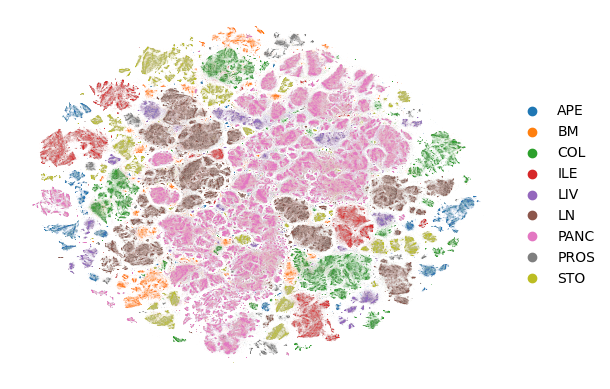

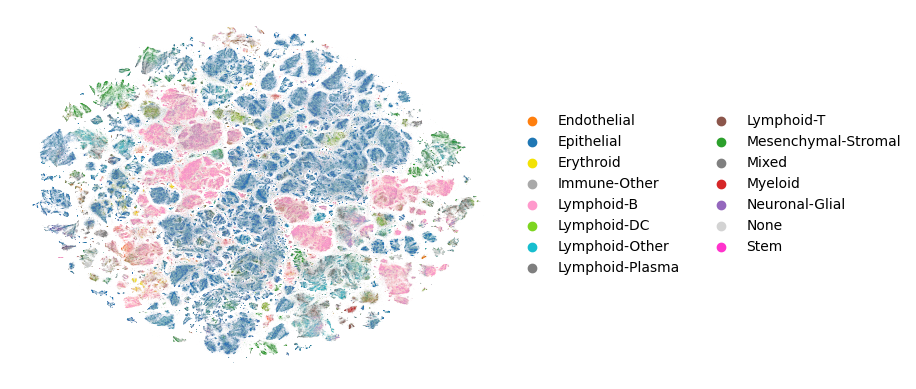

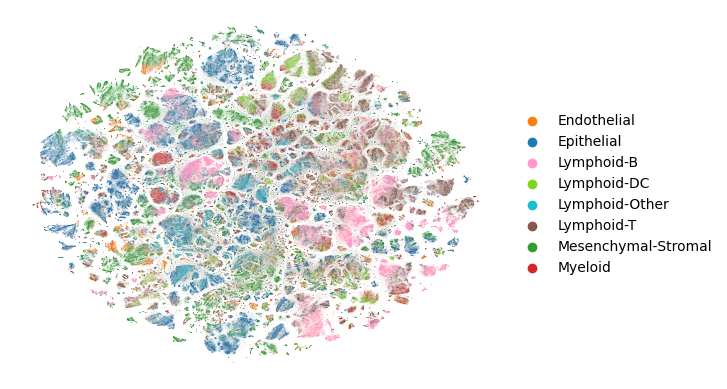

In [15]:
# 1. Organ
sc.pl.embedding(PRT, basis='X_tsne', color='organ', show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.show()

# 2. Celltype MF
sc.pl.embedding(PRT, basis='X_tsne', color='celltype_mf', palette=palette_PRTmf, show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.show()

# 3. Phenotype Broad
sc.pl.embedding(PRT, basis='X_tsne', color='phenotype_broad', palette=palette_PRTbroad, show=False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['bottom'].set_visible(False)
plt.gca().set_title('')
plt.axis('off')
plt.show()

/tmp/ipykernel_64498/4293097373.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = data.groupby(['organ', 'phenotype_broad']).size().unstack(fill_value=0)


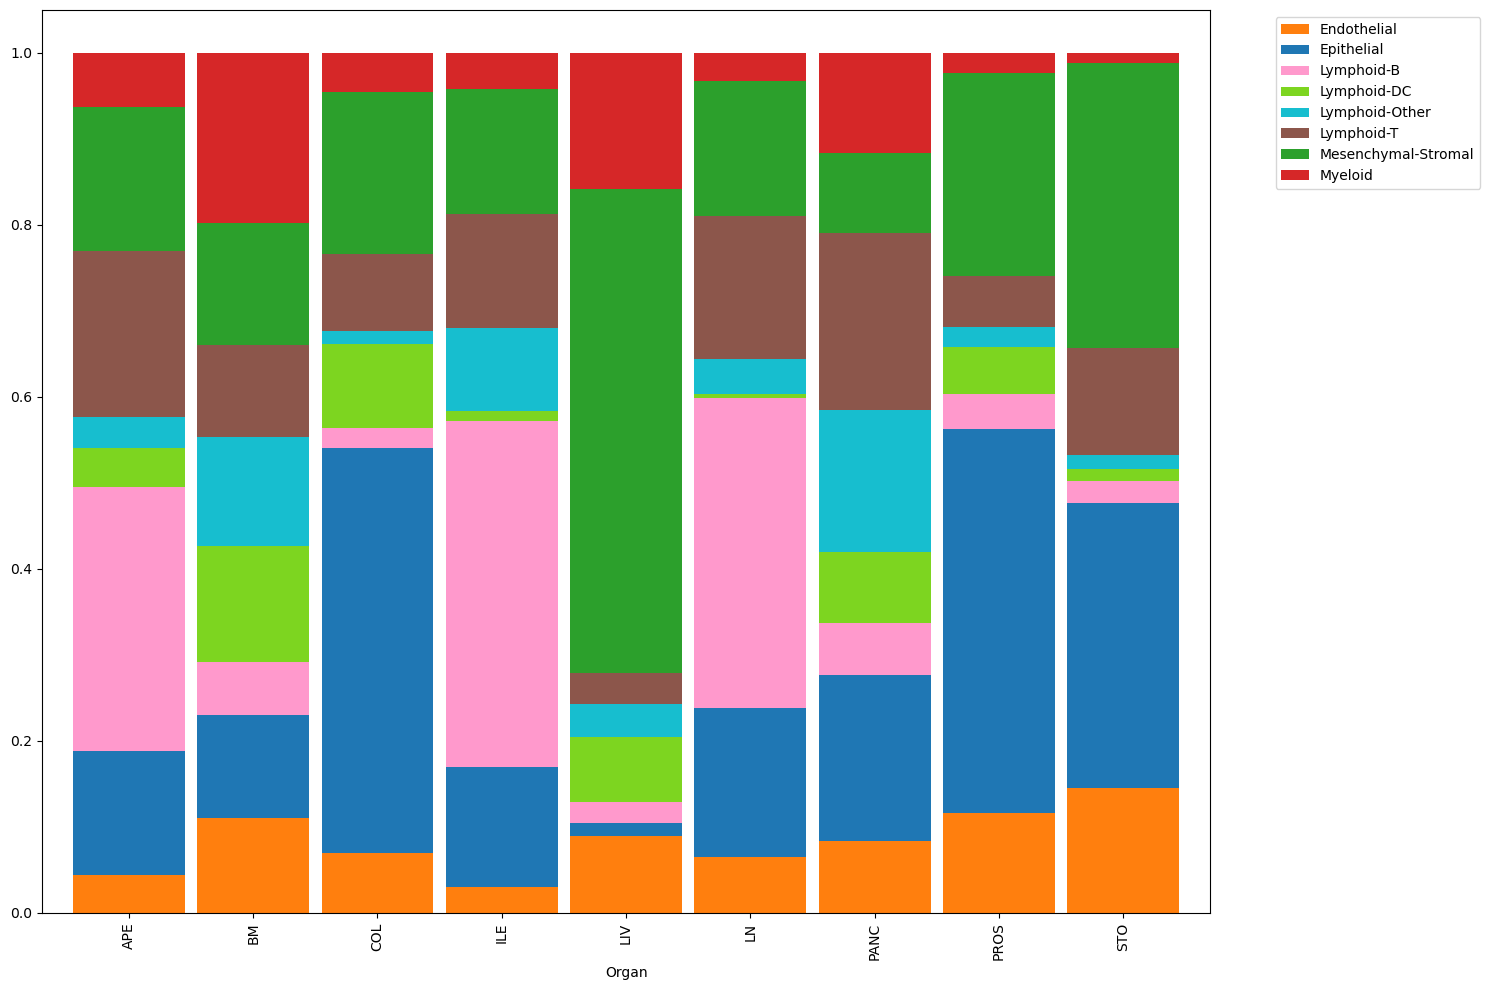

In [30]:
# Extract relevant columns
data = PRT.obs[['phenotype_broad', 'organ']]

# Group by organ and phenotype_broad and count the number of cells
counts = data.groupby(['organ', 'phenotype_broad']).size().unstack(fill_value=0)

# Compute row-wise proportions
proportions = counts.div(counts.sum(axis=1), axis=0)

# Define phenotype order that matches your palette
ordered_phenotypes = [
    'Endothelial', 'Epithelial', 'Lymphoid-B', 'Lymphoid-DC', 'Lymphoid-Other', 'Lymphoid-T', 'Mesenchymal-Stromal', 'Myeloid'
]

# Apply the order to the proportions dataframe
proportions = proportions[ordered_phenotypes]

# Define the custom palette to match the phenotype order
palette_PRTbroad = [
    '#ff7f0e',  # Endothelial
    '#1f77b4',  # Epithelial
    '#ff99cc',  # B
    '#7DD520',  # DC
    '#17becf',  # Other
    '#8c564b',  # T
    '#2ca02c',  # Mesenchymal
    '#d62728',  # Myeloid
]

# Plot
proportions.plot(kind='bar', stacked=True, figsize=(15, 10), color=palette_PRTbroad, width=0.9)

# Format
plt.xlabel('Organ')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("SCIMAP_proportions_by_organ.pdf")
plt.show()

/tmp/ipykernel_64498/1976851048.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = data.groupby(['organ', 'celltype_mf']).size().unstack(fill_value=0)


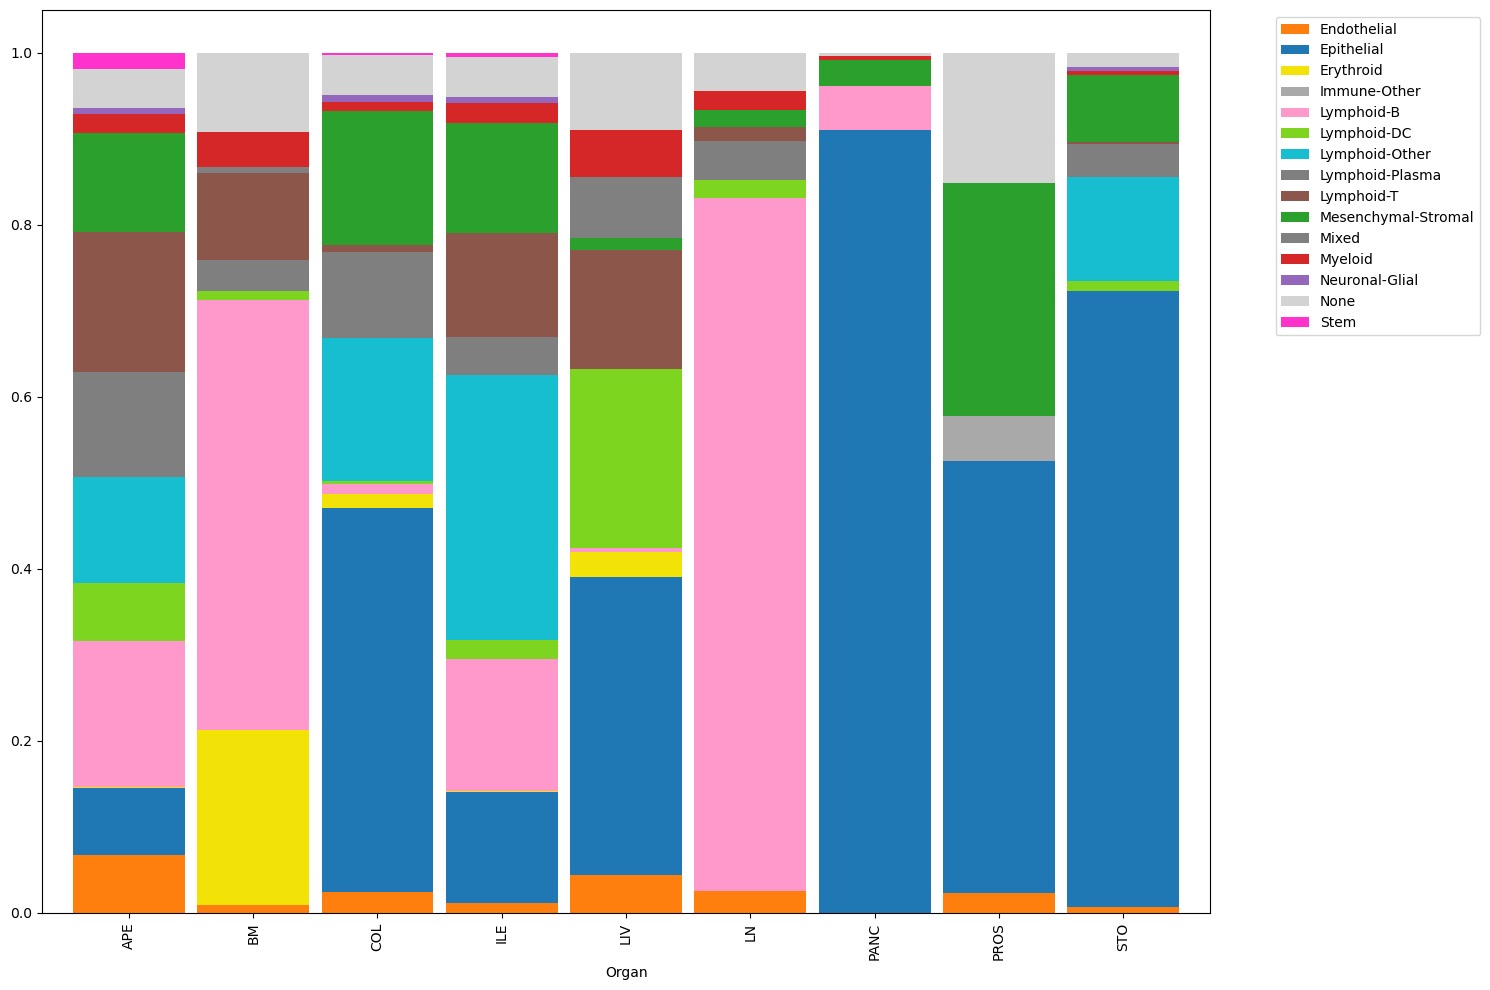

In [31]:
# Extract relevant columns
data = PRT.obs[['celltype_mf', 'organ']]

# Group by organ and phenotype_broad and count the number of cells
counts = data.groupby(['organ', 'celltype_mf']).size().unstack(fill_value=0)

# Compute row-wise proportions
proportions = counts.div(counts.sum(axis=1), axis=0)

# Define phenotype order that matches your palette
ordered_phenotypes = [
    'Endothelial', 'Epithelial', 'Erythroid', 'Immune-Other',
    'Lymphoid-B', 'Lymphoid-DC', 'Lymphoid-Other', 'Lymphoid-Plasma',
    'Lymphoid-T', 'Mesenchymal-Stromal', 'Mixed', 'Myeloid', 'Neuronal-Glial',
    'None', 'Stem'
]

# Apply the order to the proportions dataframe
proportions = proportions[ordered_phenotypes]

# Define the custom palette to match the phenotype order
palette_PRTmf = [
    '#ff7f0e', #endo
    '#1f77b4', #epi
    '#f2e205', #ery
    'darkgray', #immune
    '#ff99cc', #B
    '#7DD520', #DC
    '#17becf', #Other
    '#7f7f7f', #Plasma
    '#8c564b', #T
    '#2ca02c', #Mesen
    'gray', #mixed
    '#d62728', #Myeloid
    '#9467bd', #Neuro
    'lightgray', #None
    '#ff33cc', #Stem
]

# Plot
proportions.plot(kind='bar', stacked=True, figsize=(15, 10), color=palette_PRTmf, width=0.9)

# Format
plt.xlabel('Organ')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("MaxFuse_proportions_by_organ.pdf")
plt.show()